# k-Nearest Neighbors (k-NN) on a Kaggle Dataset

This notebook explores k-NN classification using the **Breast Cancer Wisconsin (Diagnostic) Dataset** (widely available on [Kaggle](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data)). 

To ensure this notebook runs seamlessly without requiring you to configure Kaggle API keys (`kaggle.json`), we load the exact same dataset via `scikit-learn`. We will use **Principal Component Analysis (PCA)** to reduce the high-dimensional data to 2D so we can visualize the decision boundaries, perform cross-validation on the full dataset, and evaluate the model using precision, recall, and confusion matrices.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

import warnings
warnings.filterwarnings('ignore')

## 1. Load and Standardize Data
k-NN relies on distance calculations (like Euclidean distance). If features are on different scales (e.g., one feature ranges from 0-1 and another from 0-1000), the larger feature will dominate the distance metric. Therefore, **standardizing the data is crucial**.

In [14]:
# Load dataset
data = pd.read_csv(r"C:\Users\omm91\Downloads\drug200.csv")  # Change 1
X, y = data.drop('Drug', axis=1), pd.factorize(data['Drug'])[0]
# Standardize features
X = pd.get_dummies(X, drop_first=True)  # Change 3
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dataset shape: {X_scaled.shape}")

Dataset shape: (200, 6)


## 2. Visualizing Decision Boundaries (Using PCA)
Because our dataset has 30 features, we can't plot it in 2D. We use PCA to extract the 2 most important components just for the sake of visualizing how different values of $k$ affect the decision boundary.

In [15]:
print("y datatype:", y.dtype)
print("y values:", np.unique(y))

print("Z datatype:", Z.dtype)
print("Z values:", np.unique(Z))

y datatype: int64
y values: [0 1 2 3 4]
Z datatype: object
Z values: ['DrugY' 'drugA' 'drugB' 'drugC' 'drugX']


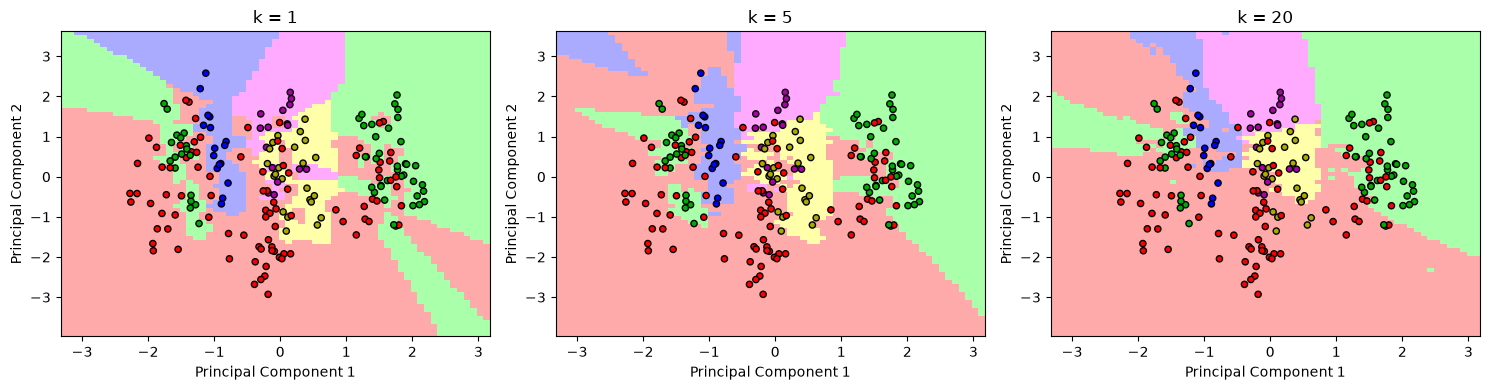

In [16]:
# Reduce to 2 dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

k_values = [1, 5, 20]

# Colors for 5 drug classes
cmap_light = ListedColormap([
    '#FFAAAA', '#AAAAFF', '#AAFFAA', '#FFFFAA', '#FFAAFF'
])

cmap_bold = ListedColormap([
    '#FF0000', '#0000FF', '#00AA00', '#AAAA00', '#AA00AA'
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.1),
    np.arange(y_min, y_max, 0.1)
)

for ax, k in zip(axes, k_values):
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_pca, y)

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.pcolormesh(xx, yy, Z, cmap=cmap_light, shading='auto')

    ax.scatter(
        X_pca[:, 0], X_pca[:, 1],
        c=y, cmap=cmap_bold,
        edgecolor='k', s=20
    )

    ax.set_title(f"k = {k}")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

## 3. Tuning $k$ on the Full Dataset
Now we use the full 30-dimensional dataset to find the optimal $k$ using 10-fold cross-validation.

The optimal number of neighbors is 18 with an accuracy of 0.9350


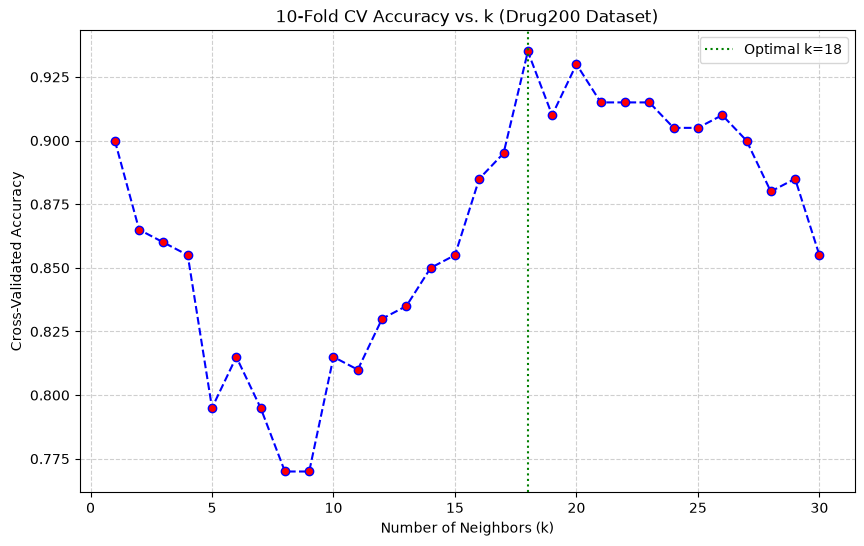

In [17]:
k_range = range(1, 31)
cv_scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    # Using the full scaled dataset (X_scaled)
    scores = cross_val_score(knn, X_scaled, y, cv=10, scoring='accuracy')
    cv_scores.append(scores.mean())

optimal_k = k_range[np.argmax(cv_scores)]
print(f"The optimal number of neighbors is {optimal_k} with an accuracy of {max(cv_scores):.4f}")

plt.figure(figsize=(10, 6))
plt.plot(k_range, cv_scores, marker='o', linestyle='dashed', color='blue', markerfacecolor='red')
plt.title('10-Fold CV Accuracy vs. k (Drug200 Dataset)')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Cross-Validated Accuracy')
plt.axvline(optimal_k, color='green', linestyle=':', label=f'Optimal k={optimal_k}')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

## 4. Model Evaluation (Precision, Recall, F1-Score & Confusion Matrix)
Cross-validation gives us a good estimate of accuracy, but in medical datasets like Breast Cancer, we care heavily about **Recall** (minimizing false negatives, i.e., not missing a malignant tumor). Let's do a standard train/test split, train our best model, and look at the detailed classification report and confusion matrix.

Classification Report for k=18:

              precision    recall  f1-score   support

       DrugY       0.94      0.89      0.91        18
       drugA       1.00      1.00      1.00         3
       drugB       0.85      1.00      0.92        11
       drugC       0.80      0.80      0.80         5
       drugX       1.00      0.67      0.80         3

    accuracy                           0.90        40
   macro avg       0.92      0.87      0.89        40
weighted avg       0.91      0.90      0.90        40



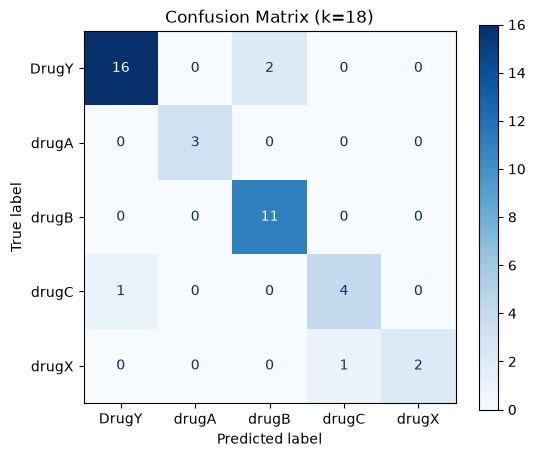

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Split data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

# 2. Train the model using the optimal k found previously (or default to 7 if undefined)
try:
    best_k = optimal_k
except NameError:
    best_k = 7

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train, y_train)

# 3. Make predictions on the test set
y_pred = knn_best.predict(X_test)

# 4. Print Classification Report
print(f"Classification Report for k={best_k}:\n")
print(classification_report(y_test, y_pred, target_names=np.unique(data['Drug'])))

# 5. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(data['Drug']))

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f"Confusion Matrix (k={best_k})")
plt.show()

## 5. The Curse of Dimensionality
As the number of features (dimensions) grows, the distance between the nearest and farthest data points becomes almost identical, causing k-NN to lose its predictive power.

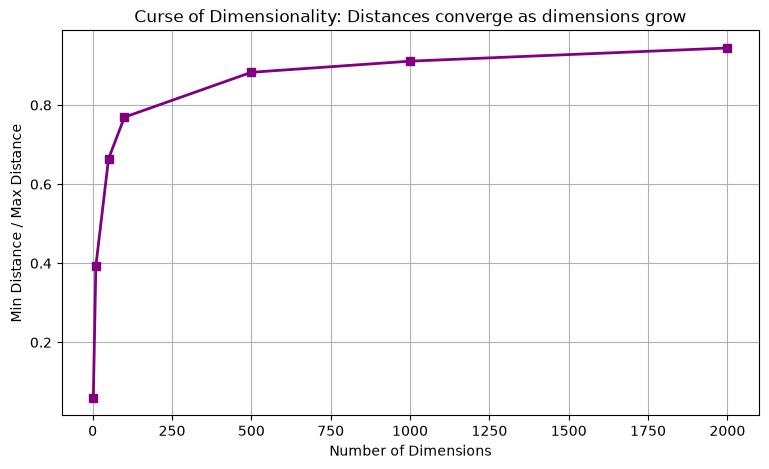

In [19]:
dimensions = [2, 10, 50, 100, 500, 1000, 2000]
ratios = []
num_points = 500

for d in dimensions:
    points = np.random.rand(num_points, d)
    distances = np.linalg.norm(points, axis=1)
    ratios.append(np.min(distances) / np.max(distances))

plt.figure(figsize=(9, 5))
plt.plot(dimensions, ratios, color='purple', marker='s', linewidth=2)
plt.xlabel('Number of Dimensions')
plt.ylabel('Min Distance / Max Distance')
plt.title('Curse of Dimensionality: Distances converge as dimensions grow')
plt.grid(True)
plt.show()